Dataset Shape: (10000, 14)


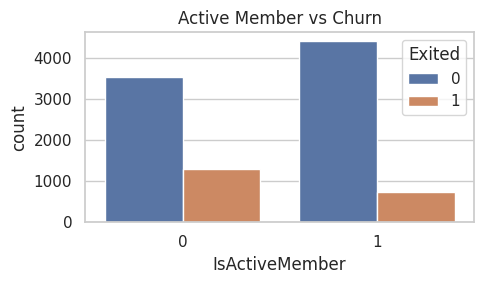

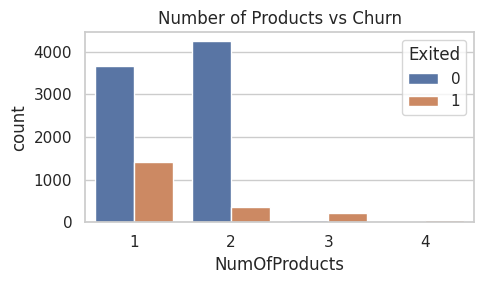

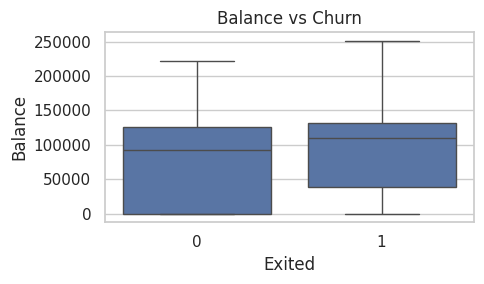

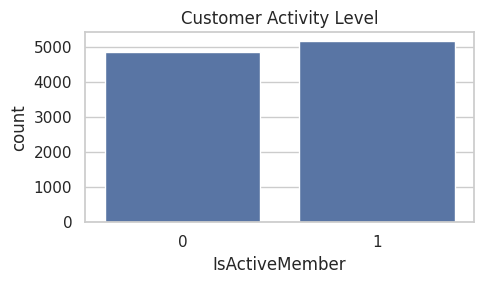

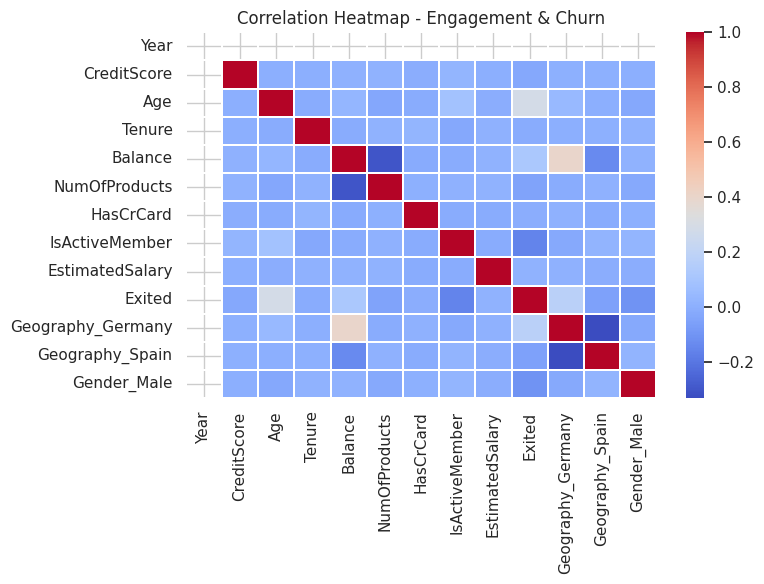

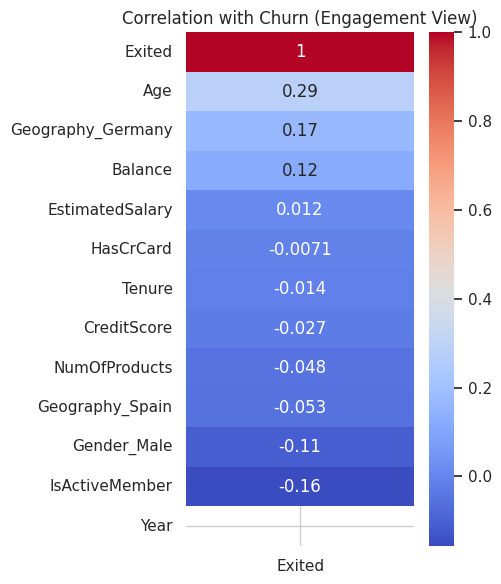


===== KEY INSIGHTS =====

- Low engagement increases churn risk
- Multi-product users show higher retention
- Active members are less likely to churn
- Engagement is a strong retention factor


In [1]:
# =========================
# CUSTOMER ENGAGEMENT ANALYSIS (EDA)
# =========================

# -------------------------
# IMPORT LIBRARIES
# -------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# -------------------------
# LOAD DATA
# -------------------------
df = pd.read_csv("European_Bank.csv.csv")

print("Dataset Shape:", df.shape)

# -------------------------
# DATA CLEANING
# -------------------------
df = df.drop(columns=[col for col in ['CustomerId', 'Surname'] if col in df.columns])

# -------------------------
# ENCODING
# -------------------------
df_encoded = pd.get_dummies(df, drop_first=True)

# -------------------------
# ACTIVE MEMBER vs ENGAGEMENT (CHURN VIEW)
# -------------------------
plt.figure(figsize=(5,3))
sns.countplot(x='IsActiveMember', hue='Exited', data=df)
plt.title("Active Member vs Churn")
plt.tight_layout()
plt.show()

# -------------------------
# NUMBER OF PRODUCTS vs CHURN
# -------------------------
plt.figure(figsize=(5,3))
sns.countplot(x='NumOfProducts', hue='Exited', data=df)
plt.title("Number of Products vs Churn")
plt.tight_layout()
plt.show()

# -------------------------
# BALANCE vs ENGAGEMENT (CHURN VIEW)
# -------------------------
plt.figure(figsize=(5,3))
sns.boxplot(x='Exited', y='Balance', data=df)
plt.title("Balance vs Churn")
plt.tight_layout()
plt.show()

# -------------------------
# ENGAGEMENT INSIGHT: ACTIVE STATUS
# -------------------------
plt.figure(figsize=(5,3))
sns.countplot(x='IsActiveMember', data=df)
plt.title("Customer Activity Level")
plt.tight_layout()
plt.show()

# -------------------------
# 🔥 CORRELATION HEATMAP (FIXED VISUAL)
# -------------------------
plt.figure(figsize=(8,6))

corr = df_encoded.corr()

sns.heatmap(corr, cmap='coolwarm', linewidths=0.3)

plt.title("Correlation Heatmap - Engagement & Churn")
plt.tight_layout()

plt.savefig("project3_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

# -------------------------
# CORRELATION WITH TARGET (CLEAN INSIGHT VIEW)
# -------------------------
corr_target = corr['Exited'].sort_values(ascending=False)

plt.figure(figsize=(5,6))
sns.heatmap(corr_target.to_frame(), annot=True, cmap='coolwarm')

plt.title("Correlation with Churn (Engagement View)")
plt.tight_layout()

plt.savefig("project3_target_corr.png", dpi=300, bbox_inches='tight')
plt.show()

# -------------------------
# INSIGHTS PRINT
# -------------------------
print("\n===== KEY INSIGHTS =====\n")
print("- Low engagement increases churn risk")
print("- Multi-product users show higher retention")
print("- Active members are less likely to churn")
print("- Engagement is a strong retention factor")